# Customer Churn Prediction using Logistic Regression

## Machine Learning Classification Project

This project builds an end-to-end Machine Learning pipeline for predicting whether a telecommunications customer is likely to churn.

The project covers:

- Data Loading
- Data Validation
- Data Cleaning
- Exploratory Data Analysis
- Data Visualization
- Feature Engineering
- Train/Test Split
- Numerical Preprocessing
- Categorical Preprocessing
- Logistic Regression
- Model Training
- Model Evaluation
- Model Interpretation
- Model Persistence
- Prediction on New Data

In [7]:
from __future__ import annotations

import json
import logging
from pathlib import Path
from typing import Any

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [4]:
RANDOM_STATE = 42
TEST_SIZE = 0.20

DATA_PATH = Path(
    r"C:\Users\bm255\OneDrive\Desktop\logistic\WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

ARTIFACTS_DIR = Path(
    r"C:\Users\bm255\OneDrive\Desktop\logistic\artifacts"
)

MODEL_PATH = ARTIFACTS_DIR / "customer_churn_logistic_regression.joblib"
METRICS_PATH = ARTIFACTS_DIR / "customer_churn_metrics.json"

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

In [5]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}"
    )

print(f"Dataset found: {DATA_PATH}")

Dataset found: C:\Users\bm255\OneDrive\Desktop\logistic\WA_Fn-UseC_-Telco-Customer-Churn.csv


In [6]:
df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")

Dataset shape: (7043, 21)


In [8]:
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 7043
Number of columns: 21


In [10]:
print("Columns:")
for column in df.columns:
    print(column)

Columns:
customerID
gender
SeniorCitizen
Partner
Dependents
tenure
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
MonthlyCharges
TotalCharges
Churn


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [12]:
def validate_input_data(
    data: pd.DataFrame,
    target_column: str,
) -> None:
    if data.empty:
        raise ValueError("Dataset is empty.")

    if target_column not in data.columns:
        raise ValueError(
            f"Target column '{target_column}' does not exist."
        )

    if data[target_column].nunique(dropna=True) < 2:
        raise ValueError(
            "Target column must contain at least two classes."
        )

    print("Dataset validation passed.")

In [13]:
TARGET_COLUMN = "Churn"

validate_input_data(
    data=df,
    target_column=TARGET_COLUMN,
)

Dataset validation passed.


In [14]:
missing_values = df.isna().sum()

display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

,missing_count


In [15]:
for column in df.columns:
    unique_values = df[column].dropna().unique()

    print(f"{column}:")
    print(unique_values[:10])
    print(f"Number of unique values: {df[column].nunique()}")
    print("-" * 60)

customerID:
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' '7795-CFOCW' '9237-HQITU'
 '9305-CDSKC' '1452-KIOVK' '6713-OKOMC' '7892-POOKP' '6388-TABGU']
Number of unique values: 7043
------------------------------------------------------------
gender:
['Female' 'Male']
Number of unique values: 2
------------------------------------------------------------
SeniorCitizen:
[0 1]
Number of unique values: 2
------------------------------------------------------------
Partner:
['Yes' 'No']
Number of unique values: 2
------------------------------------------------------------
Dependents:
['No' 'Yes']
Number of unique values: 2
------------------------------------------------------------
tenure:
[ 1 34  2 45  8 22 10 28 62 13]
Number of unique values: 73
------------------------------------------------------------
PhoneService:
['No' 'Yes']
Number of unique values: 2
------------------------------------------------------------
MultipleLines:
['No phone service' 'No' 'Yes']
Number of unique values: 3


In [16]:
display(df.describe())

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [17]:
churn_counts = df[TARGET_COLUMN].value_counts()

display(churn_counts.to_frame("count"))

,count
Churn,
No,5174
Yes,1869


In [18]:
churn_percentages = (
    df[TARGET_COLUMN]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("percentage")
)

display(churn_percentages)

,percentage
Churn,
No,73.46
Yes,26.54


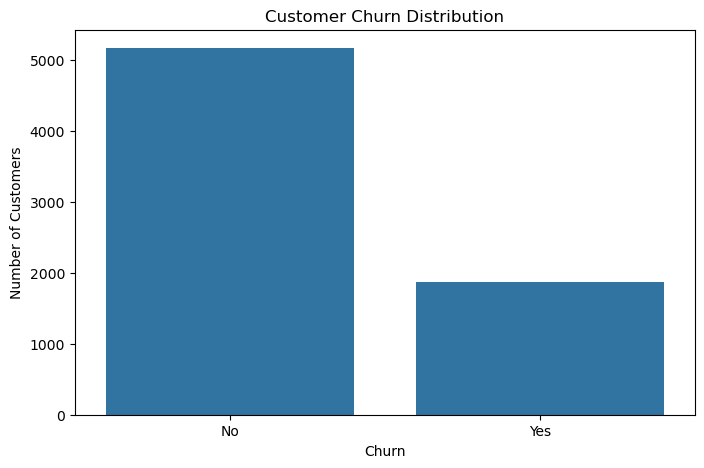

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=TARGET_COLUMN,
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [20]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce",
)

print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isna().sum())

Data type: float64
Missing values: 11


In [21]:
display(
    df.dtypes.to_frame("data_type")
)

,data_type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [22]:
df = df.drop(
    columns=["customerID"]
)

print(f"Dataset shape: {df.shape}")

Dataset shape: (7043, 20)


In [23]:
X = df.drop(
    columns=[TARGET_COLUMN]
)

y = df[TARGET_COLUMN]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (7043, 19)
Target shape: (7043,)


In [24]:
def detect_column_types(
    features: pd.DataFrame,
) -> tuple[list[str], list[str]]:
    numeric_columns = features.select_dtypes(
        include=[np.number]
    ).columns.tolist()

    categorical_columns = features.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    return numeric_columns, categorical_columns

In [25]:
numeric_features, categorical_features = detect_column_types(
    X
)

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (5634, 19)
X_test shape: (1409, 19)
y_train shape: (5634,)
y_test shape: (1409,)


In [27]:
train_distribution = y_train.value_counts(
    normalize=True
).mul(100).round(2)

test_distribution = y_test.value_counts(
    normalize=True
).mul(100).round(2)

distribution_comparison = pd.DataFrame(
    {
        "train_percentage": train_distribution,
        "test_percentage": test_distribution,
    }
)

display(distribution_comparison)

,train_percentage,test_percentage
Churn,,
No,73.46,73.46
Yes,26.54,26.54


In [28]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            ),
        ),
        (
            "scaler",
            StandardScaler(),
        ),
    ]
)

In [29]:
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            ),
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
        ),
    ]
)

In [30]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features,
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features,
        ),
    ]
)

In [31]:
def build_model() -> LogisticRegression:
    return LogisticRegression(
        C=1.0,
        max_iter=2000,
        penalty="l2",
        random_state=RANDOM_STATE,
    )

In [32]:
model = build_model()

print(model)

LogisticRegression(max_iter=2000, random_state=42)


In [33]:
def build_pipeline(
    preprocessor: ColumnTransformer,
    model: LogisticRegression,
) -> Pipeline:
    return Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model),
        ]
    )

In [34]:
pipeline = build_pipeline(
    preprocessor=preprocessor,
    model=model,
)

pipeline

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [35]:
pipeline.fit(
    X_train,
    y_train,
)

print("Model training completed.")

Model training completed.


In [36]:
y_pred = pipeline.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']


In [37]:
y_proba = pipeline.predict_proba(X_test)

print("First 5 probability predictions:")
print(y_proba[:5])

First 5 probability predictions:
[[0.95470613 0.04529387]
 [0.31558874 0.68441126]
 [0.94127926 0.05872074]
 [0.59829576 0.40170424]
 [0.97845228 0.02154772]]


In [38]:
classes = pipeline.named_steps["model"].classes_

print("Classes:")
print(classes)

Classes:
['No' 'Yes']


In [39]:
positive_class = "Yes"

positive_class_index = np.where(
    classes == positive_class
)[0][0]

y_churn_proba = y_proba[:, positive_class_index]

print("First 10 churn probabilities:")
print(y_churn_proba[:10])

First 10 churn probabilities:
[0.04529387 0.68441126 0.05872074 0.40170424 0.02154772 0.60393536
 0.44922498 0.13005522 0.00288077 0.39517899]


In [40]:
predictions_df = pd.DataFrame(
    {
        "actual": y_test.to_numpy(),
        "prediction": y_pred,
        "churn_probability": y_churn_proba,
    },
    index=X_test.index,
)

display(predictions_df.head(10))

,actual,prediction,churn_probability
437,No,No,0.045294
2280,No,Yes,0.684411
2235,No,No,0.058721
4460,No,No,0.401704
3761,No,No,0.021548
5748,No,Yes,0.603935
3568,No,No,0.449225
2976,No,No,0.130055
5928,No,No,0.002881
1639,Yes,No,0.395179


In [41]:
accuracy = accuracy_score(
    y_test,
    y_pred,
)

print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.8055


In [42]:
precision = precision_score(
    y_test,
    y_pred,
    pos_label=positive_class,
    zero_division=0,
)

print(f"Precision: {precision:.4f}")

Precision: 0.6572


In [43]:
recall = recall_score(
    y_test,
    y_pred,
    pos_label=positive_class,
    zero_division=0,
)

print(f"Recall: {recall:.4f}")

Recall: 0.5588


In [44]:
f1 = f1_score(
    y_test,
    y_pred,
    pos_label=positive_class,
    zero_division=0,
)

print(f"F1 Score: {f1:.4f}")

F1 Score: 0.6040


In [45]:
roc_auc = roc_auc_score(
    (y_test == positive_class).astype(int),
    y_churn_proba,
)

print(f"ROC-AUC: {roc_auc:.4f}")

ROC-AUC: 0.8419


In [46]:
metrics_df = pd.DataFrame(
    {
        "metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score",
            "ROC-AUC",
        ],
        "value": [
            accuracy,
            precision,
            recall,
            f1,
            roc_auc,
        ],
    }
)

display(metrics_df)

,metric,value
0,Accuracy,0.805536
1,Precision,0.657233
2,Recall,0.558824
3,F1 Score,0.604046
4,ROC-AUC,0.841861


In [47]:
print(
    classification_report(
        y_test,
        y_pred,
        digits=4,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

          No     0.8488    0.8947    0.8711      1035
         Yes     0.6572    0.5588    0.6040       374

    accuracy                         0.8055      1409
   macro avg     0.7530    0.7268    0.7376      1409
weighted avg     0.7979    0.8055    0.8002      1409



In [48]:
confusion_matrix_values = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"],
)

print(confusion_matrix_values)

[[926 109]
 [165 209]]


<Figure size 700x500 with 0 Axes>

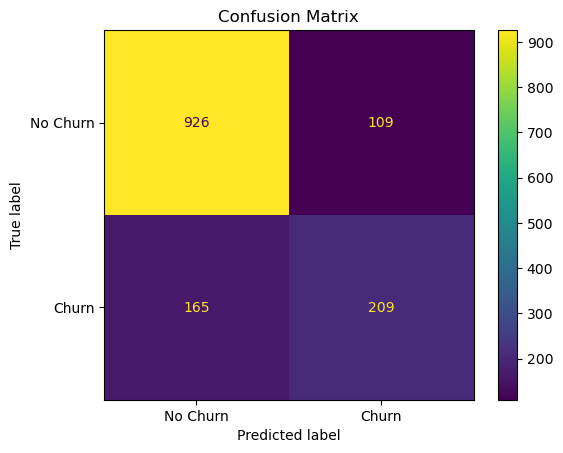

In [49]:
plt.figure(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_values,
    display_labels=["No Churn", "Churn"],
).plot()

plt.title("Confusion Matrix")
plt.show()

In [50]:
tn, fp, fn, tp = confusion_matrix_values.ravel()

confusion_matrix_details = pd.DataFrame(
    {
        "case": [
            "True Negative",
            "False Positive",
            "False Negative",
            "True Positive",
        ],
        "value": [
            tn,
            fp,
            fn,
            tp,
        ],
    }
)

display(confusion_matrix_details)

,case,value
0,True Negative,926
1,False Positive,109
2,False Negative,165
3,True Positive,209


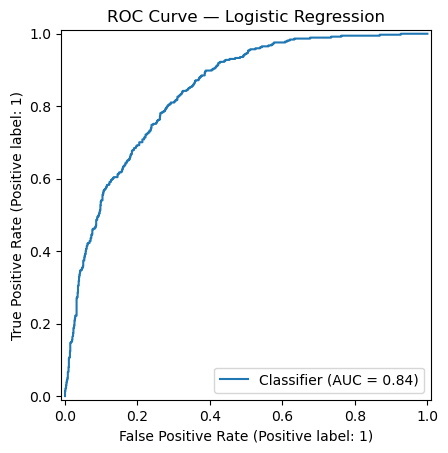

In [51]:
y_test_binary = (
    y_test == positive_class
).astype(int)

RocCurveDisplay.from_predictions(
    y_test_binary,
    y_churn_proba,
)

plt.title("ROC Curve — Logistic Regression")
plt.show()

In [52]:
roc_auc

0.8418610659019866

In [53]:
feature_names = pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

print(f"Number of transformed features: {len(feature_names)}")

Number of transformed features: 45


In [54]:
coefficients = pipeline.named_steps[
    "model"
].coef_[0]

print(f"Number of coefficients: {len(coefficients)}")

Number of coefficients: 45


In [55]:
coefficient_df = pd.DataFrame(
    {
        "feature": feature_names,
        "coefficient": coefficients,
    }
)

display(coefficient_df)

,feature,coefficient
0,numeric__SeniorCitizen,0.053929
1,numeric__tenure,-1.241319
2,numeric__MonthlyCharges,-0.596392
3,numeric__TotalCharges,0.516708
4,categorical__gender_Female,-0.167742
5,categorical__gender_Male,-0.145719
6,categorical__Partner_No,-0.167934
7,categorical__Partner_Yes,-0.145528
8,categorical__Dependents_No,-0.043130
9,categorical__Dependents_Yes,-0.270331


In [56]:
coefficient_df["absolute_coefficient"] = (
    coefficient_df["coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="absolute_coefficient",
    ascending=False,
)

display(
    coefficient_df.head(20)
)

,feature,coefficient,absolute_coefficient
1,numeric__tenure,-1.241319,1.241319
38,categorical__Contract_Two year,-0.772261,0.772261
15,categorical__InternetService_DSL,-0.652406,0.652406
16,categorical__InternetService_Fiber optic,0.640026,0.640026
2,numeric__MonthlyCharges,-0.596392,0.596392
36,categorical__Contract_Month-to-month,0.579304,0.579304
3,numeric__TotalCharges,0.516708,0.516708
39,categorical__PaperlessBilling_No,-0.343260,0.343260
22,categorical__OnlineBackup_No internet service,-0.301082,0.301082
17,categorical__InternetService_No,-0.301082,0.301082


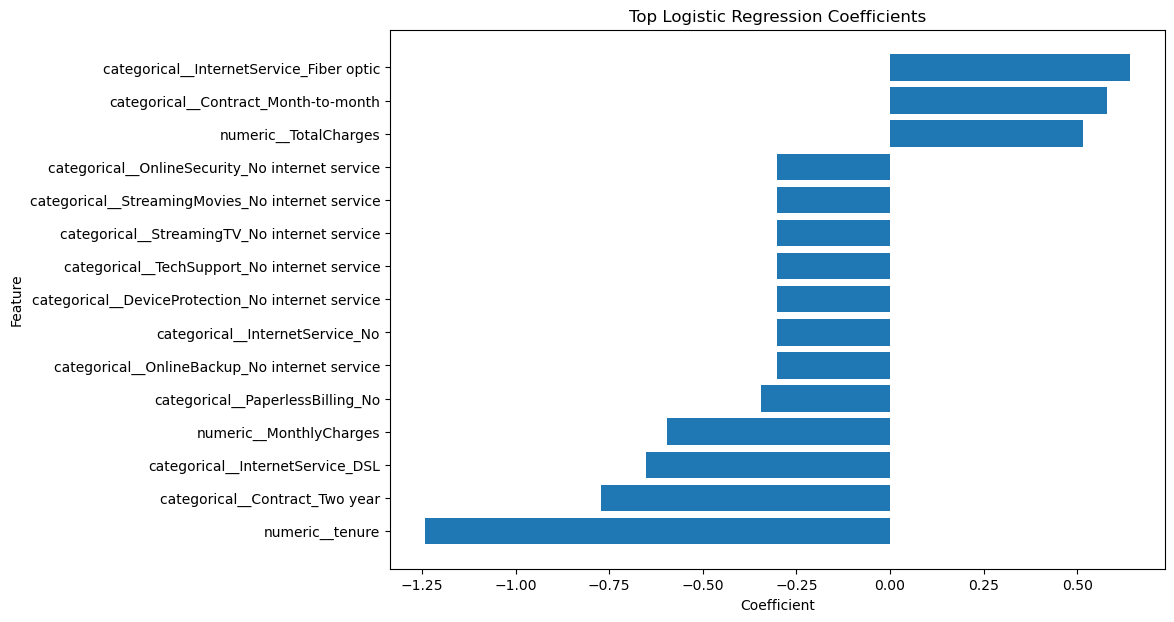

In [57]:
top_coefficients = (
    coefficient_df
    .head(15)
    .sort_values("coefficient")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_coefficients["feature"],
    top_coefficients["coefficient"],
)

plt.title("Top Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.show()

In [58]:
metrics = {
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": roc_auc,
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp),
}

In [59]:
display(
    pd.DataFrame(
        [metrics]
    ).T.rename(
        columns={0: "value"}
    )
)

,value
accuracy,0.805536
precision,0.657233
recall,0.558824
f1_score,0.604046
roc_auc,0.841861
true_negative,926.000000
false_positive,109.000000
false_negative,165.000000
true_positive,209.000000


In [60]:
joblib.dump(
    pipeline,
    MODEL_PATH,
)

print(f"Model saved to: {MODEL_PATH}")

Model saved to: C:\Users\bm255\OneDrive\Desktop\logistic\artifacts\customer_churn_logistic_regression.joblib


In [61]:
with open(
    METRICS_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metrics,
        file,
        indent=4,
    )

print(f"Metrics saved to: {METRICS_PATH}")

Metrics saved to: C:\Users\bm255\OneDrive\Desktop\logistic\artifacts\customer_churn_metrics.json


In [62]:
print("Saved artifacts:")

for path in ARTIFACTS_DIR.iterdir():
    print(path.name)

Saved artifacts:
customer_churn_logistic_regression.joblib
customer_churn_metrics.json


In [63]:
loaded_pipeline = joblib.load(
    MODEL_PATH
)

print("Model loaded successfully.")

Model loaded successfully.


In [64]:
sample_customer = X_test.iloc[[0]]

sample_prediction = loaded_pipeline.predict(
    sample_customer
)[0]

print(f"Prediction: {sample_prediction}")

Prediction: No


In [65]:
sample_probabilities = loaded_pipeline.predict_proba(
    sample_customer
)[0]

sample_churn_probability = sample_probabilities[
    positive_class_index
]

print(
    f"Churn probability: {sample_churn_probability:.2%}"
)

Churn probability: 4.53%


In [66]:
sample_result = sample_customer.copy()

sample_result["actual_churn"] = y_test.loc[
    sample_customer.index
].iloc[0]

sample_result["predicted_churn"] = sample_prediction

sample_result["churn_probability"] = (
    sample_churn_probability
)

display(sample_result.T)

,437
gender,Male
SeniorCitizen,0
Partner,Yes
Dependents,Yes
tenure,72
PhoneService,Yes
MultipleLines,Yes
InternetService,Fiber optic
OnlineSecurity,Yes
OnlineBackup,Yes


In [67]:
with open(
    METRICS_PATH,
    "r",
    encoding="utf-8",
) as file:
    saved_metrics = json.load(file)

display(
    pd.DataFrame(
        [saved_metrics]
    ).T.rename(
        columns={0: "value"}
    )
)

,value
accuracy,0.805536
precision,0.657233
recall,0.558824
f1_score,0.604046
roc_auc,0.841861
true_negative,926.000000
false_positive,109.000000
false_negative,165.000000
true_positive,209.000000


In [68]:
def predict_customer_churn(
    pipeline: Pipeline,
    customer_data: pd.DataFrame,
    positive_class: str,
) -> dict[str, Any]:
    prediction = pipeline.predict(customer_data)[0]
    probabilities = pipeline.predict_proba(customer_data)[0]
    classes = pipeline.named_steps["model"].classes_

    positive_index = np.where(
        classes == positive_class
    )[0][0]

    return {
        "prediction": prediction,
        "churn_probability": float(
            probabilities[positive_index]
        ),
    }

In [69]:
customer = X_test.iloc[[0]]

result = predict_customer_churn(
    pipeline=loaded_pipeline,
    customer_data=customer,
    positive_class=positive_class,
)

print(f"Prediction: {result['prediction']}")
print(
    f"Churn probability: "
    f"{result['churn_probability']:.2%}"
)

Prediction: No
Churn probability: 4.53%
